In [3]:
!pip install -q pandas numpy scikit-learn matplotlib joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:

df = pd.read_csv("/content/nifty500_processed_data.csv")

print(df.head())
print("Dataset shape:", df.shape)
print(df.isnull().sum())


         Date  Ticker        Open        High         Low       Close  \
0  2021-06-09  360ONE  260.813755  262.150806  249.887157  251.816010   
1  2021-06-10  360ONE  253.997012  260.046642  251.848943  257.131409   
2  2021-06-11  360ONE  259.443804  263.246739  256.714877  260.758942   
3  2021-06-14  360ONE  261.931602  263.027550  258.939658  259.619141   
4  2021-06-15  360ONE  260.791773  260.791773  252.144728  253.821533   

     Volume  Ticker_Encoded  
0   59152.0               0  
1   41084.0               0  
2  232800.0               0  
3   74364.0               0  
4  149636.0               0  
Dataset shape: (551643, 8)
Date              0
Ticker            0
Open              0
High              0
Low               0
Close             0
Volume            0
Ticker_Encoded    0
dtype: int64


In [5]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumber of unique stocks:", df["Ticker"].nunique())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 551643 entries, 0 to 551642
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Date            551643 non-null  object 
 1   Ticker          551643 non-null  object 
 2   Open            551643 non-null  float64
 3   High            551643 non-null  float64
 4   Low             551643 non-null  float64
 5   Close           551643 non-null  float64
 6   Volume          551643 non-null  float64
 7   Ticker_Encoded  551643 non-null  int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 33.7+ MB

Missing values:
Date              0
Ticker            0
Open              0
High              0
Low               0
Close             0
Volume            0
Ticker_Encoded    0
dtype: int64

Duplicate rows: 0

Number of unique stocks: 500

Date range:
2021-06-09 to 2026-06-09

Statistical summary:


,Open,High,Low,Close,Volume,Ticker_Encoded
count,551643.000000,551643.000000,551643.000000,551643.000000,5.516430e+05,551643.000000
mean,1882.927583,1908.446096,1855.072520,1880.521817,5.929137e+06,248.394525
std,6610.161851,6678.209196,6531.022663,6600.118226,2.790023e+07,144.161233
min,3.500000,3.650000,3.350000,3.500000,2.370000e+02,0.000000
25%,246.780998,251.451467,242.128479,246.402252,2.484385e+05,123.000000
50%,631.138124,641.790427,620.500000,630.408203,8.441400e+05,247.000000
75%,1470.415559,1492.066060,1447.570744,1468.885010,3.261656e+06,374.000000
max,161973.590589,163593.537167,160278.657659,162288.578125,1.807991e+09,499.000000


In [ ]:
# Clean column names
df.columns = df.columns.str.strip()

# Convert Date and Close
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df["Close"] = pd.to_numeric(df["Close"], errors="coerce")

# Standardize stock tickers
df["Ticker"] = df["Ticker"].astype(str).str.strip().str.upper()

# Remove invalid records
df = df.dropna(subset=["Date", "Ticker", "Close"])

df = df[df["Close"] > 0]

# Sort by stock and date
df = df.sort_values(["Ticker", "Date"])

# Remove duplicate stock-date entries
df = df.drop_duplicates(
    subset=["Ticker", "Date"],
    keep="last"
)

df = df.reset_index(drop=True)

print("Data cleaning completed!")

print("Final dataset shape:", df.shape)

print("Unique stocks:", df["Ticker"].nunique())

display(df.head())

Data cleaning completed!
Final dataset shape: (551643, 8)
Unique stocks: 500


,Date,Ticker,Open,High,Low,Close,Volume,Ticker_Encoded
0,2021-06-09,360ONE,260.813755,262.150806,249.887157,251.816010,59152.0,0
1,2021-06-10,360ONE,253.997012,260.046642,251.848943,257.131409,41084.0,0
2,2021-06-11,360ONE,259.443804,263.246739,256.714877,260.758942,232800.0,0
3,2021-06-14,360ONE,261.931602,263.027550,258.939658,259.619141,74364.0,0
4,2021-06-15,360ONE,260.791773,260.791773,252.144728,253.821533,149636.0,0


In [ ]:
# Store each stock's historical data separately
stock_data = {}

for ticker, stock in df.groupby("Ticker"):

    stock = stock.sort_values("Date").copy()

    # Convert dates into elapsed days
    stock["Days"] = (
        stock["Date"] - stock["Date"].min()
    ).dt.days

    stock_data[ticker] = stock

print("Stock data prepared successfully!")

print("Total stocks:", len(stock_data))

print("Example stock:", list(stock_data.keys())[:5])

Stock data prepared successfully!
Total stocks: 500
Example stock: ['360ONE', '3MINDIA', 'AADHARHFC', 'AARTIIND', 'AAVAS']


In [ ]:
models = {}
metrics = {}
skipped_stocks = []

for ticker, stock in stock_data.items():

    if len(stock) < 30:
        skipped_stocks.append(ticker)
        continue

    X = stock[["Days"]]
    y = stock["Close"]

    # Chronological 80:20 split
    split = int(len(stock) * 0.80)

    X_train = X.iloc[:split]
    X_test = X.iloc[split:]

    y_train = y.iloc[:split]
    y_test = y.iloc[split:]

    # Train testing model
    test_model = LinearRegression()

    test_model.fit(X_train, y_train)

    # Test predictions
    predictions = test_model.predict(X_test)

    # Evaluation metrics
    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    mape = mean_absolute_percentage_error(
        y_test, predictions
    ) * 100

    r2 = r2_score(y_test, predictions)

    # Naive baseline
    baseline_predictions = np.full(
        len(y_test), y_train.iloc[-1]
    )

    baseline_mae = mean_absolute_error(
        y_test, baseline_predictions
    )

    metrics[ticker] = {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2,
        "Baseline_MAE": baseline_mae
    }

    # Final model trained on all available data
    final_model = LinearRegression()

    final_model.fit(X, y)

    models[ticker] = {
        "model": final_model,
        "origin_date": stock["Date"].min(),
        "latest_date": stock["Date"].max(),
        "latest_close": float(y.iloc[-1]),
        "observations": len(stock)
    }

print("Linear Regression training completed!")

print("Models trained:", len(models))

print("Stocks skipped:", len(skipped_stocks))

Linear Regression training completed!
Models trained: 500
Stocks skipped: 0


In [ ]:
print("Available trained stock models:")

print(list(models.keys())[:20])

print("\nExample model: RELIANCE")

if "RELIANCE" in models:

    print("Latest close:",
          models["RELIANCE"]["latest_close"])

    print("Latest date:",
          models["RELIANCE"]["latest_date"])

    print("Observations:",
          models["RELIANCE"]["observations"])

    print("Model:",
          models["RELIANCE"]["model"])

Available trained stock models:
['360ONE', '3MINDIA', 'AADHARHFC', 'AARTIIND', 'AAVAS', 'ABB', 'ABBOTINDIA', 'ABCAPITAL', 'ABDL', 'ABFRL', 'ABLBL', 'ABREL', 'ABSLAMC', 'ACC', 'ACE', 'ACMESOLAR', 'ACUTAAS', 'ADANIENSOL', 'ADANIENT', 'ADANIGREEN']

Example model: RELIANCE
Latest close: 1269.199951171875
Latest date: 2026-06-09 00:00:00
Observations: 1234
Model: LinearRegression()


In [ ]:
ticker = "RELIANCE"

if ticker in models:

    stock_model = models[ticker]

    model = stock_model["model"]

    latest_day = stock_model["observations"]

    print("Stock:", ticker)
    print("Latest Close:", stock_model["latest_close"])
    print("Latest Date:", stock_model["latest_date"])

    print("Model:", model)

else:
    print("Stock model not found")

Stock: RELIANCE
Latest Close: 1269.199951171875
Latest Date: 2026-06-09 00:00:00
Model: LinearRegression()


In [ ]:
ticker = "RELIANCE"

stock_model = models[ticker]

model = stock_model["model"]

# Calculate last_day as the elapsed days from origin_date to latest_date
last_day = (stock_model["latest_date"] - stock_model["origin_date"]).days

future_days = 30

future_price = model.predict(
    pd.DataFrame({
        "Days": [last_day + future_days]
    })
)[0]

print("Stock:", ticker)
print("Current Price:", stock_model["latest_close"])
print("Predicted Price:", round(future_price, 2))

Stock: RELIANCE
Current Price: 1269.199951171875
Predicted Price: 1479.1


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

ticker = "RELIANCE"

# Retrieve from stock_data which contains the 'Days' column instead of df
stock = stock_data[ticker]

split = int(len(stock) * 0.8)

X_test = stock[["Days"]].iloc[split:]
y_test = stock["Close"].iloc[split:]

predictions = models[ticker]["model"].predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))

print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))

print("R2 Score:", r2_score(y_test, predictions))

MAE: 68.35017372545532
RMSE: 82.21652858338658
R2 Score: -0.35142555043177426


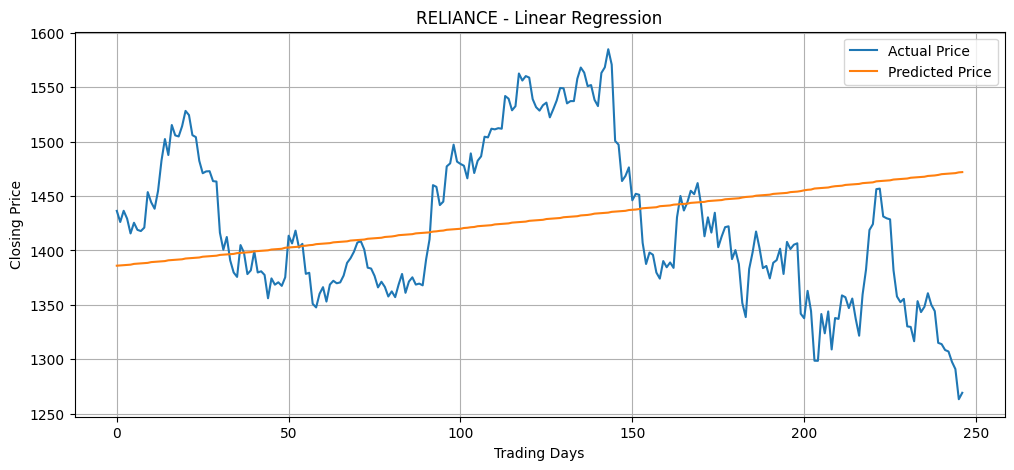

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label="Actual Price")

plt.plot(predictions, label="Predicted Price")

plt.title("RELIANCE - Linear Regression")

plt.xlabel("Trading Days")
plt.ylabel("Closing Price")

plt.legend()
plt.grid()

plt.show()